# 

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as mlt
import seaborn as ss

In [37]:
c_df = pd.read_csv('/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv')
c_df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [38]:
df = c_df.copy()

In [39]:
c_df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

In [40]:
c_df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [41]:
c_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [42]:
c_df.describe(include='all')

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<1H OCEAN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9136
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909,NaN
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874,NaN
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,NaN
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000,NaN
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000,NaN
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000,NaN


Take a look at he min and max values of Total_rooms, Total_bedrooms, Population these columns have too little minimum values while
too large max values. Maybe these features have outliers we will further check this too. 

In [43]:
c_df.nunique()

longitude               844
latitude                862
housing_median_age       52
total_rooms            5926
total_bedrooms         1923
population             3888
households             1815
median_income         12928
median_house_value     3842
ocean_proximity           5
dtype: int64

Take a quick look on columns that have extreme values and less values

In [44]:
c = ['total_rooms', 'total_bedrooms', 'population', 'households', 'housing_median_age', 'ocean_proximity']

for col in c:
    print(f"=== Unique Value Counts for: {col} ===")
    print(pd.DataFrame(c_df[col].value_counts(dropna=False).head(10)))

=== Unique Value Counts for: total_rooms ===
             count
total_rooms       
1527.0          18
1613.0          17
1582.0          17
2127.0          16
2053.0          15
1722.0          15
1607.0          15
1717.0          15
1471.0          15
1703.0          15
=== Unique Value Counts for: total_bedrooms ===
                count
total_bedrooms       
NaN               207
280.0              55
331.0              51
345.0              50
343.0              49
393.0              49
328.0              48
348.0              48
394.0              48
309.0              47
=== Unique Value Counts for: population ===
            count
population       
891.0          25
1052.0         24
761.0          24
850.0          24
1227.0         24
825.0          23
999.0          22
1005.0         22
782.0          22
1098.0         21
=== Unique Value Counts for: households ===
            count
households       
306.0          57
335.0          56
386.0          56
282.0          55
429

Take a look at Ocean_Proximity

In [45]:
c_df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

**ISLAND** has only 5 values.

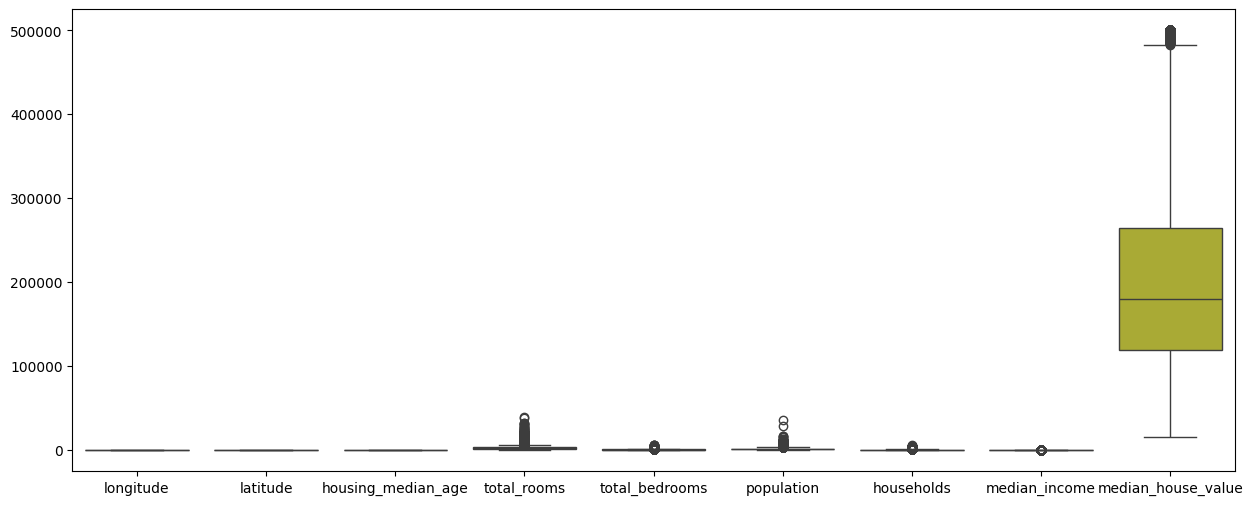

In [46]:
mlt.figure(figsize = (15,6))
ss.boxplot(data = c_df)
mlt.show()

Now as we can see **median house value** has much more influence over the others. To resolve this 
appropirate scaling method will be used later. However first null values will be checked and cleared

In [47]:
c_df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Filling Null Values

In [48]:
c_df['total_bedrooms'] = c_df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [49]:
c_df.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

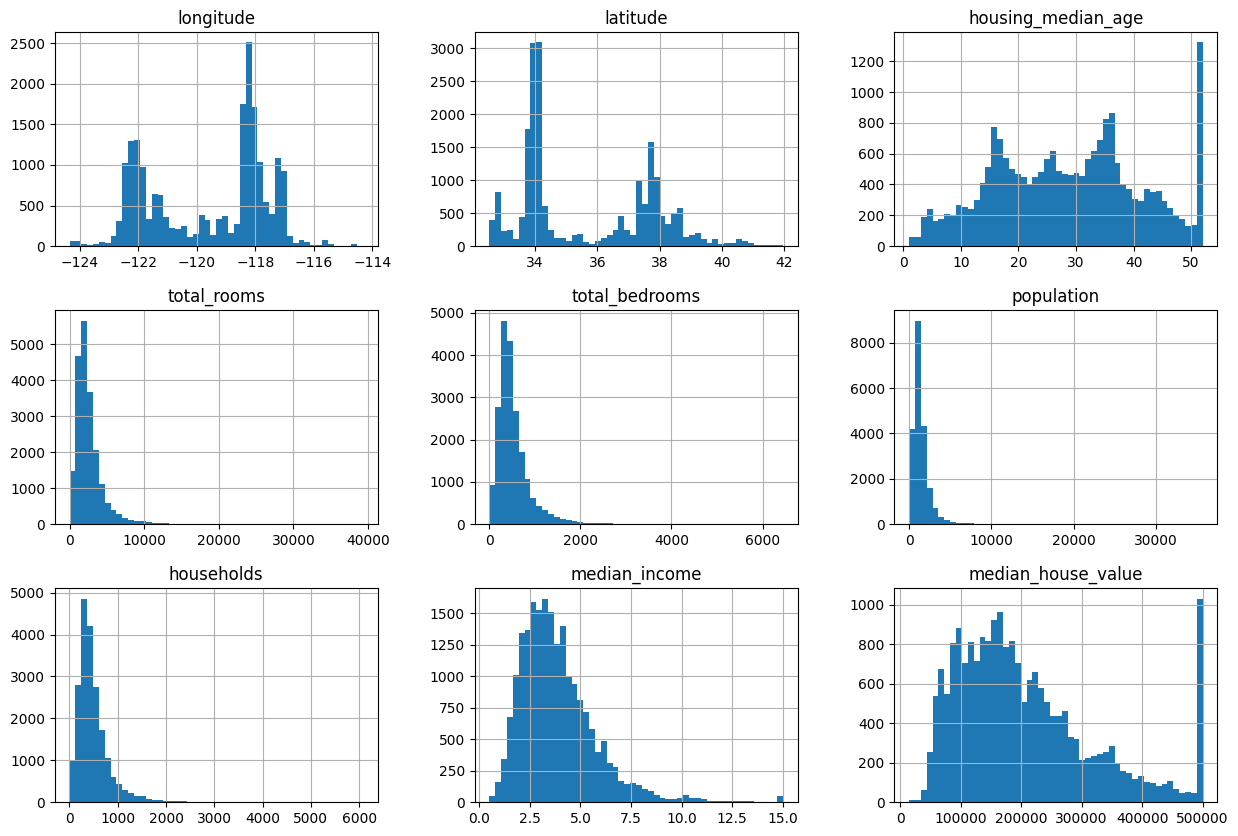

In [50]:
c_df.hist(figsize=(15,10),bins = 50)

* All the features are skewed However **median_house_value** and **median_house_age** are **capped** at the end.
* Features **Longitude** and **Lattitude** have **two peeks**.

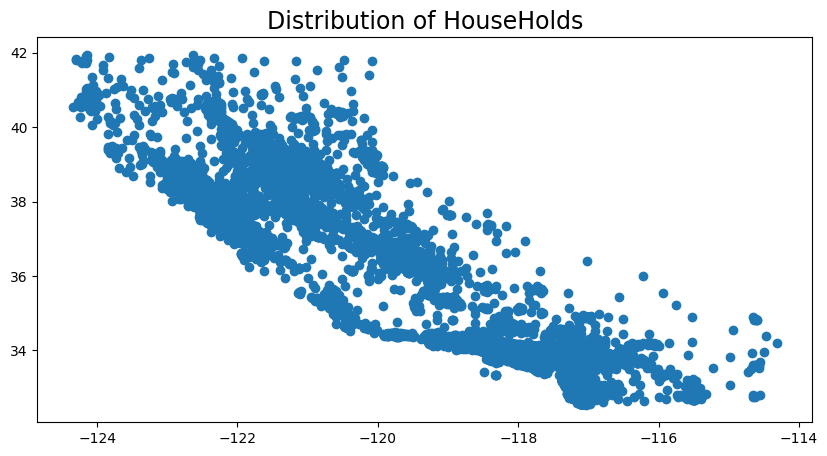

In [51]:
mlt.figure(figsize=(10,5))
mlt.scatter(x=c_df['longitude'], y=c_df["latitude"])
mlt.title('Distribution of HouseHolds',size=17)
mlt.show()

****EDA****

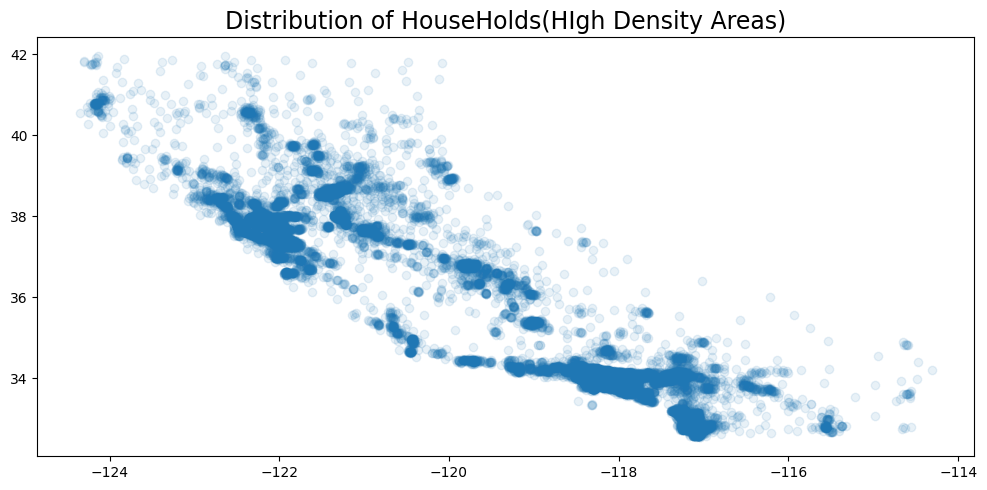

In [52]:
mlt.figure(figsize=(10,5))
mlt.scatter(x=c_df['longitude'], y=c_df["latitude"],alpha=0.1)
mlt.title('Distribution of HouseHolds(HIgh Density Areas)',size=17)
mlt.tight_layout()
mlt.show()

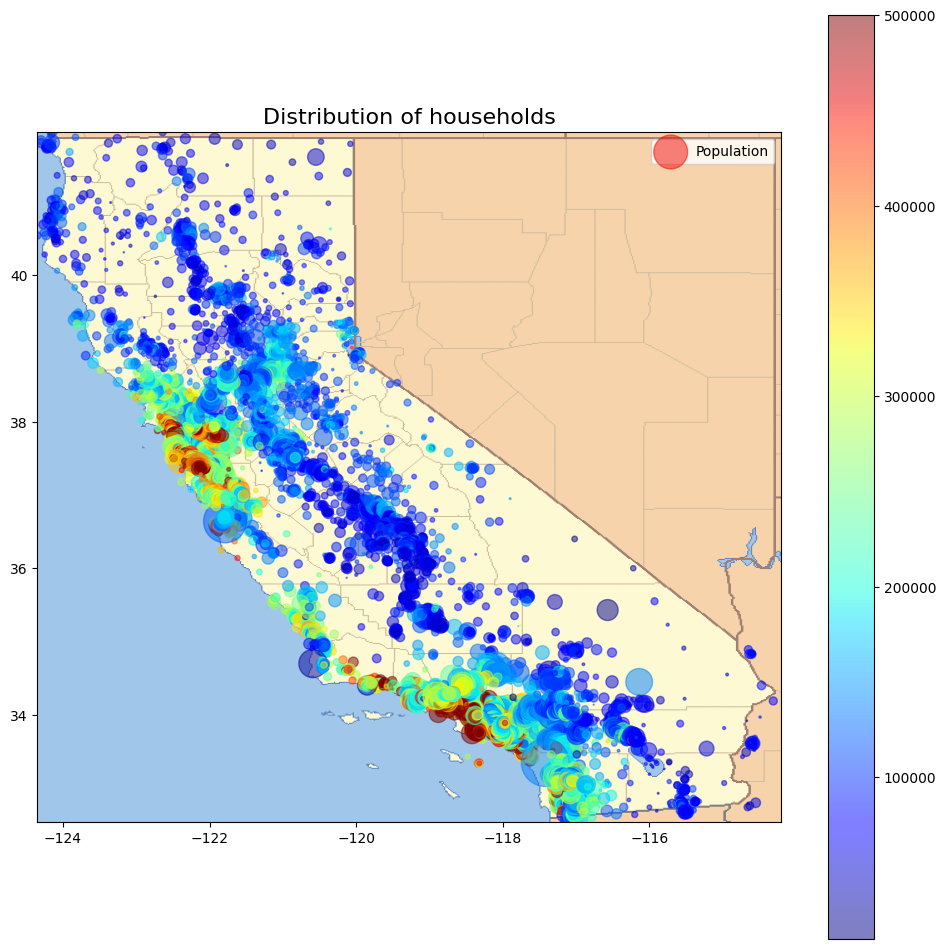

In [53]:
mlt.figure(figsize=(12,12))
img=mlt.imread('/kaggle/input/datasets/muhammadzubairjutt/california-picture/california.png')
mlt.imshow(img,zorder=0,extent=[-124.35,-114.2,32.54,41.95])
mlt.scatter(x=c_df['longitude'],y=c_df['latitude'],alpha=0.5,s=c_df['population']/30,c=c_df['median_house_value'],
            cmap=mlt.get_cmap("jet"),zorder=1,label='Population')
mlt.colorbar()
mlt.title("Distribution of households",size=16)
mlt.legend()

* Now it is clear that *House Prices* are much related to *location* and *population*
* Prices are also higher near ocean except North side.

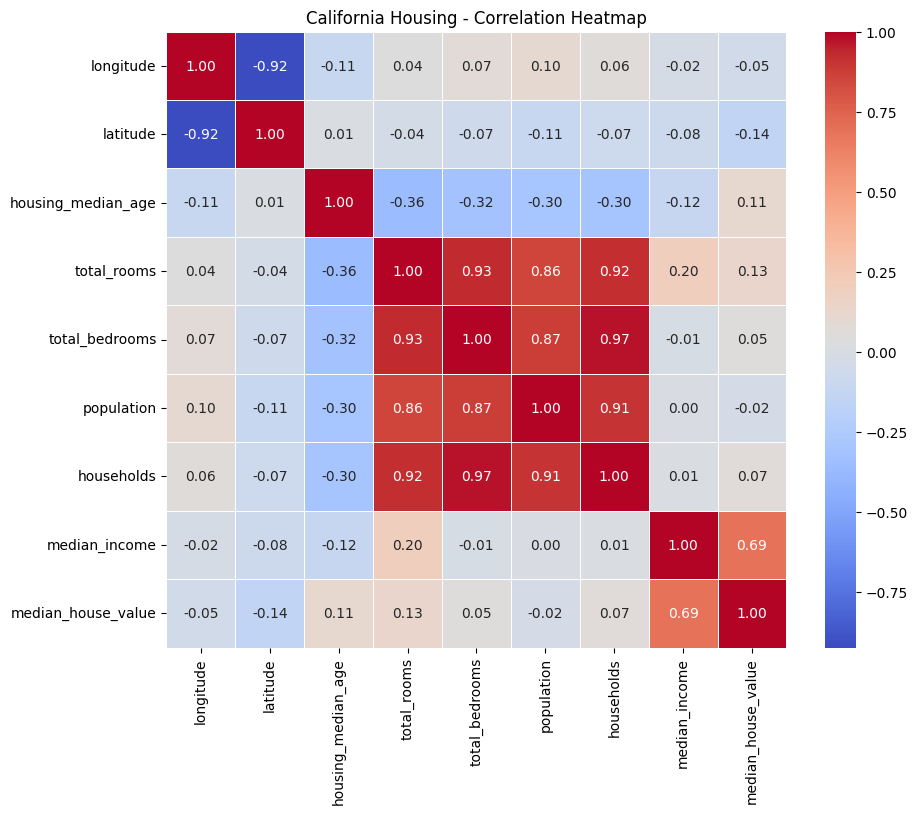

In [54]:
# correlation matrix 
mlt.figure(figsize=(10, 8))
correlation_matrix = c_df.select_dtypes(include=[np.number]).corr()

#Heat Map
ss.heatmap(correlation_matrix, annot=True, cmap='coolwarm',fmt=".2f", linewidths=0.5)
mlt.title("California Housing - Correlation Heatmap")
mlt.show()

**Encoding**

In [55]:
c_df_encoded = pd.get_dummies(c_df, columns = ['ocean_proximity'], drop_first=True)
c_df_encoded.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,False,False,True,False


In [56]:
c_df_encoded[['ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']] = c_df_encoded[['ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']].astype(int)

In [57]:
c_df_encoded.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,1,0


In [58]:
from sklearn.model_selection import train_test_split
X = c_df_encoded.drop(columns=['median_house_value'])
y = c_df_encoded["median_house_value"]

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)
print("Training features shape: ", X_train.shape)
print('Testing features shape: ', X_test.shape)

Training features shape:  (16512, 12)
Testing features shape:  (4128, 12)


**Standardization**

In [60]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [61]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Scaled: ", X_train_scaled.shape)

Scaled:  (16512, 12)


**Grid Search CV**

In [62]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV


In [63]:
alphas = [0.01, 0.1,1.0, 10.0, 100.0]
ridge = Ridge()
ridge_grid = GridSearchCV(estimator=ridge, param_grid={'alpha':alphas}, cv=5, 
                                                      scoring = 'neg_root_mean_squared_error')
ridge_grid.fit(X_train_scaled, y_train)
print('Best Ridge Alpha: ', ridge_grid.best_params_)

Best Ridge Alpha:  {'alpha': 10.0}


In [64]:
lasso = Lasso(max_iter= 10000)
lasso_grid = GridSearchCV(estimator = lasso, param_grid={'alpha': alphas},cv =5, 
                         scoring = "neg_root_mean_squared_error")
lasso_grid.fit(X_train_scaled, y_train)
print("Best Lasso Alpha: ", lasso_grid.best_params_)

Best Lasso Alpha:  {'alpha': 10.0}


**Evalutaion**

In [65]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ridge_pred = ridge_grid.predict(X_test_scaled)
lasso_pred = lasso_grid.predict(X_test_scaled) # predictions 

In [66]:
ridge_rm = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_r2 = r2_score(y_test, ridge_pred)

In [67]:
print("Ridge Metrics Evaluation")
print(f"RMSE: {ridge_rm:.2f}")
print(f"MAE: {ridge_mae:.2f}")
print(f"R_square score: {ridge_r2:.4f}\n")

Ridge Metrics Evaluation
RMSE: 70031.31
MAE: 50646.17
R_square score: 0.6257



In [68]:
lasso_rm = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)

In [69]:
print('Lasso Metrics Evaluation')
print(f"RMSE: {lasso_rm:.2f}")
print(f"MAE: {lasso_mae:.2f}")
print(f"R_square score: {lasso_r2:.4f}\n")

Lasso Metrics Evaluation
RMSE: 70053.90
MAE: 50664.70
R_square score: 0.6255



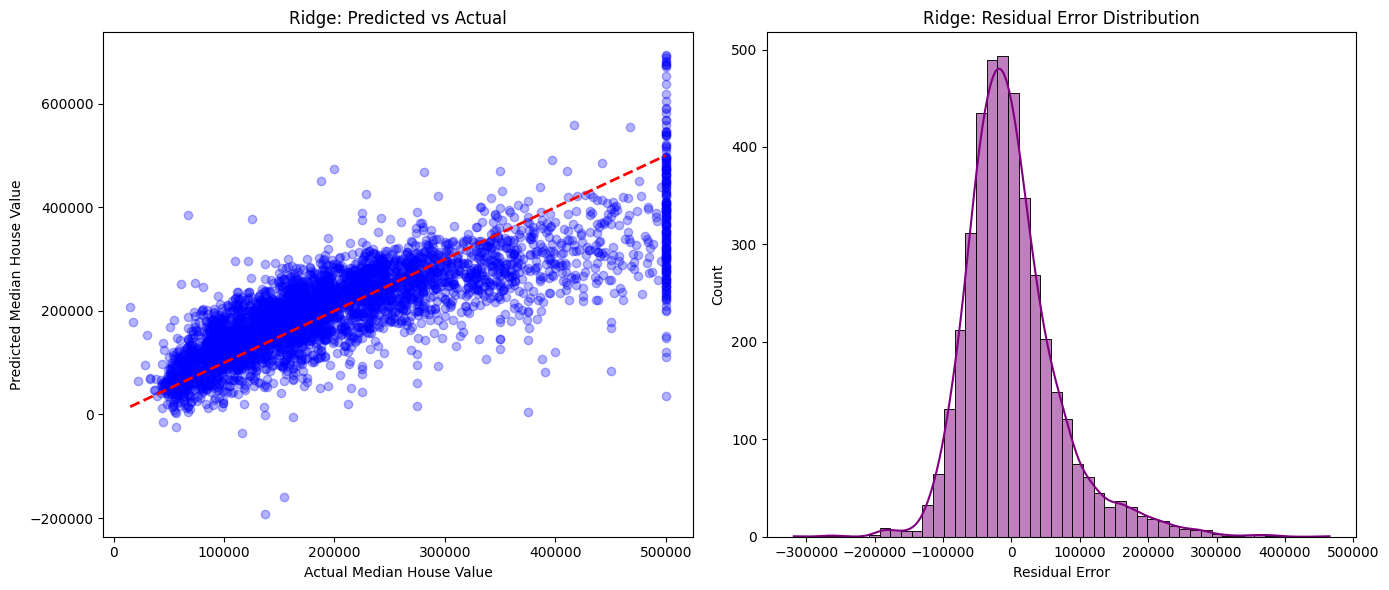

In [70]:
fig, axes = mlt.subplots(1, 2, figsize=(14, 6))

# 1. Predicted vs Actual Plot (Ridge)
axes[0].scatter(y_test, ridge_pred, alpha=0.3, color='blue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Median House Value')
axes[0].set_ylabel('Predicted Median House Value')
axes[0].set_title('Ridge: Predicted vs Actual')


residuals = y_test - ridge_pred
ss.histplot(residuals, kde=True, ax=axes[1], color='purple', bins=50)
axes[1].set_xlabel('Residual Error')
axes[1].set_title('Ridge: Residual Error Distribution')

mlt.tight_layout()
mlt.show()